# Vertical Jump Coach Agent — Progress Report
WatSPEED Agentic AI · Course Project · Sean Tang · due Nov 8, 2026

**Progress summary.** I am building a vertical-jump coaching agent grounded in 1,166 cleaned John Evans / THP Strength transcripts (~334 h). A LangGraph **Coach** agent searches the library as a tool and answers with every point cited to a retrieved chunk: on a 35-question evaluation every answer passed the code citation check, none cited a fabricated source, 5/5 out-of-scope questions were declined, and answers took ~9 s and ~4¢. A hand review (29 of 34 points fully supported, 5 partial, 0 contradicting) motivated a fresh-context **Verifier**. I have also built a **Planner** agent that drafts periodized programs from hand-reviewed, cited templates, passes them through 8 code checks and waits for my approval, plus a safety pre-check, router, tracing and a Streamlit UI. Next: re-evaluate with the Verifier, route chat plan requests to the Planner, add a training log, and compare against no-retrieval and single-agent baselines.

## 0. Setup
The notebook reads saved evaluation results, so it prints quickly and costs nothing. Set `RUN_LIVE = True` only to re-run the live Coach demo (needs an API key and the private transcript data).

In [1]:
import json, os, sys, inspect, subprocess, textwrap
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
RUN_LIVE = False

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titleweight": "bold"})
BLUE, TEAL, AMBER, GREY, RED = "#2a5d9f", "#1f8a70", "#d98e04", "#6b7280", "#b3402f"
pd.set_option("display.width", 120, "display.max_colwidth", 90)
print("repo:", ROOT.name)

repo: repo


## 1. Architecture
A message first passes two **code** gates (red-flag safety check, then router). Plan requests go to the Planner and everything else to the Coach. Both agents share one capped tool loop, one set of rules (`AGENTS.md`) and one fresh-context Verifier. Every run writes a local JSONL trace.

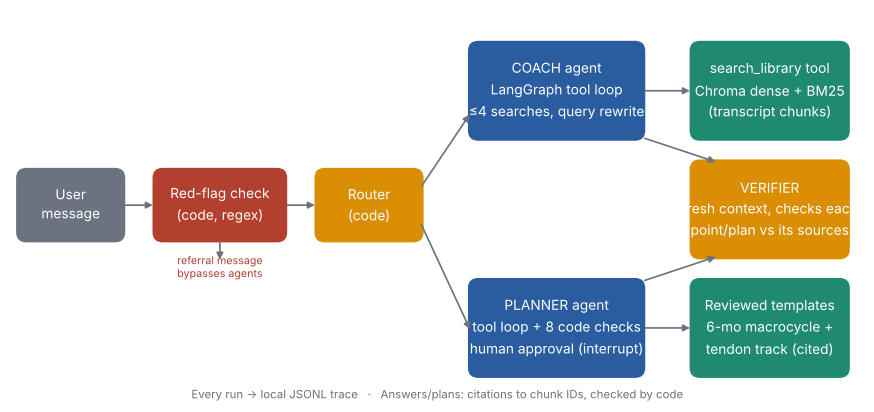

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.6)); ax.set_xlim(0, 100); ax.set_ylim(0, 46); ax.axis("off")
def box(x, y, w, h, text, color, tc="white"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.2", fc=color, ec="none"))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", color=tc, fontsize=9, linespacing=1.3)
def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=9, color=GREY, lw=1.1))

box(1, 19, 12, 8, "User\nmessage", GREY)
box(17, 19, 15, 8, "Red-flag check\n(code, regex)", RED)
box(36, 19, 12, 8, "Router\n(code)", AMBER)
box(54, 31, 20, 11, "COACH agent\nLangGraph tool loop\n≤4 searches, query rewrite", BLUE)
box(54, 3, 20, 11, "PLANNER agent\ntool loop + 8 code checks\nhuman approval (interrupt)", BLUE)
box(80, 31, 18, 11, "search_library tool\nChroma dense + BM25\n(transcript chunks)", TEAL)
box(80, 3, 18, 11, "Reviewed templates\n6-mo macrocycle +\ntendon track (cited)", TEAL)
box(80, 17, 18, 11, "VERIFIER\nfresh context, checks each\npoint/plan vs its sources", AMBER)
for a in [(13, 23, 17, 23), (32, 23, 36, 23), (48, 25, 54, 34), (48, 21, 54, 8),
          (74, 36.5, 80, 36.5), (74, 8.5, 80, 8.5), (74, 31, 83, 28), (74, 14, 83, 17)]:
    arrow(*a)
ax.text(24.5, 14.5, "referral message\nbypasses agents", ha="center", fontsize=7, color=RED)
arrow(24.5, 19, 24.5, 16.2)
ax.text(50, 0.2, "Every run → local JSONL trace   ·   Answers/plans: citations to chunk IDs, checked by code", ha="center", fontsize=7.5, color=GREY)
plt.show()

| Component | Course concept | Status |
|---|---|---|
| Coach `search_library` tool loop | Tool use, agentic RAG, query rewriting | Done, evaluated |
| Chunking + hybrid retrieval | RAG, retrieval evaluation | Done, evaluated |
| Structured output + code citation check | Guardrails, grounding | Done |
| Verifier (fresh context) | Evaluator / multi-agent review | Built, evaluation pending |
| Planner + templates + code checks | Planning, structured generation | Built, first real runs pending |
| Approval `interrupt` + versioned store | Human-in-the-loop, memory/state | Built |
| Red-flag pre-check + router | Safety guardrails, routing | Done (19 safety cases) |
| JSONL traces, tests (mocked LLM, no network) | Observability, testing | Done |

## 2. Knowledge base: the transcript dataset
Collected on my own machine (YouTube blocks cloud IPs, and rate-limited the collector twice), then cleaned with a glossary and corpus-wide fixes. The data is private, so only counts are shown here.

,John Evans,THP Strength,Total
Videos collected and cleaned,406,760,1166


1,192 listed -> 1,166 collected (25 without captions, 1 age-restricted) · ~334 hours · all auto-captions


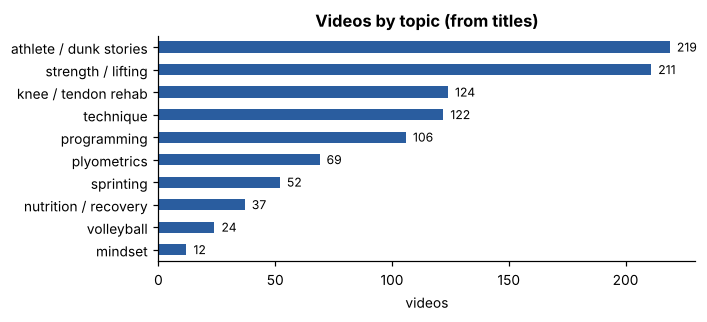

In [3]:
stats = pd.DataFrame({"John Evans": [406], "THP Strength": [760]}, index=["Videos collected and cleaned"])
stats["Total"] = stats.sum(axis=1)
display(stats)
print("1,192 listed -> 1,166 collected (25 without captions, 1 age-restricted) · ~334 hours · all auto-captions")

topics = pd.Series({"athlete / dunk stories": 219, "strength / lifting": 211, "knee / tendon rehab": 124, "technique": 122,
                    "programming": 106, "plyometrics": 69, "sprinting": 52, "nutrition / recovery": 37,
                    "volleyball": 24, "mindset": 12}).sort_values()
ax = topics.plot.barh(color=BLUE, figsize=(6.5, 3)); ax.set_title("Videos by topic (from titles)"); ax.set_xlabel("videos")
for i, v in enumerate(topics): ax.text(v + 3, i, v, va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Cleaning (`clean.py` v1.2).** Glossary rules fix systematic caption errors (e.g. *tenant/tenon → tendon*, *pio → plyo*, *Ecentric → eccentric*), filler and repeats are removed, and a `coaching_content` flag separates coaching from stories. Promo segments are flagged and kept so retrieval can down-rank them.

## 3. Retrieval experiments
Three chunkers (`timewindow`, `charsplit_350`, `charsplit_matched`) × three modes (dense with `nomic-embed-text`, BM25, hybrid with reciprocal-rank fusion), scored on 30 in-scope questions with gold time ranges. A hit means a top-k chunk overlaps a gold range. *Gold is only partly verified (8/30), so treat absolute numbers as approximate.*

,method,mode,recall@1,recall@5,recall@10,mrr
0,timewindow,dense,0.43,0.73,0.80,0.56
1,timewindow,bm25,0.10,0.47,0.63,0.23
2,timewindow,hybrid,0.37,0.63,0.77,0.49
3,charsplit_matched,dense,0.47,0.87,0.87,0.62
4,charsplit_matched,bm25,0.13,0.43,0.50,0.25
5,charsplit_matched,hybrid,0.33,0.67,0.83,0.47
6,charsplit_350,dense,0.43,0.67,0.87,0.54
7,charsplit_350,bm25,0.13,0.50,0.53,0.29
8,charsplit_350,hybrid,0.37,0.77,0.83,0.52


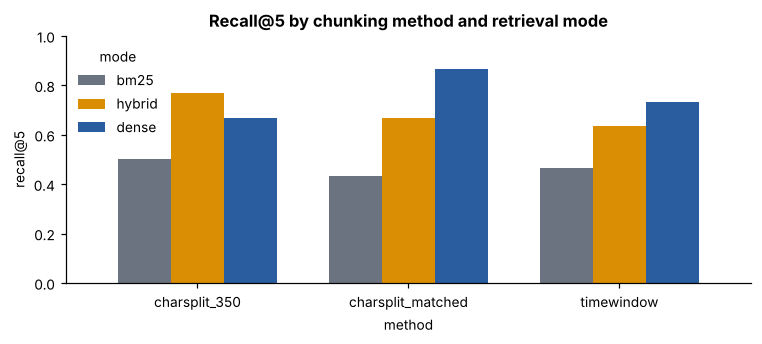

Best config: {'method': 'charsplit_matched', 'mode': 'dense'}


In [4]:
R = json.load(open("results/retrieval_eval.json"))
df = pd.DataFrame([{k: v for k, v in c.items() if k not in ("per_question", "top1_score_mean")} for c in R["configs"]])
main = df[~df["mode"].str.contains("since")]
display(main[["method", "mode", "recall@1", "recall@5", "recall@10", "mrr"]].round(2).reset_index(drop=True))

piv = main.pivot(index="method", columns="mode", values="recall@5")[["bm25", "hybrid", "dense"]]
ax = piv.plot.bar(figsize=(7, 3.2), color=[GREY, AMBER, BLUE], rot=0, width=0.75)
ax.set_title("Recall@5 by chunking method and retrieval mode"); ax.set_ylabel("recall@5"); ax.set_ylim(0, 1)
ax.legend(title="mode", frameon=False); plt.tight_layout(); plt.show()
print("Best config:", R["best"])

**Decision:** default to `charsplit_matched` + dense retrieval (recall@5 = 0.87). BM25 alone is weak (≈0.45) because viewers' words ("jumper's knee") differ from coaches' words ("patellar tendinopathy"), which is why the Coach also rewrites queries into coaching terms.

## 4. Coach agent
One LangGraph loop (`coach ↔ tools`). The model must call `search_library` (at most 4 times), then answer in a strict JSON schema: a summary, up to 3 points each with `cites`, an optional safety note, and a `not_covered` flag. Code then verifies the citations.

**Model switching** is isolated in one function; the rest of the repo never names a provider.

In [5]:
from src.llm import get_llm
print(inspect.getsource(get_llm))

def get_llm(role: str = "coach", model_spec: str | None = None) -> BaseChatModel:
    """Build the chat model for an agent role.

    model_spec overrides the role's env var (used by scripts/compare_models.py
    to run the same role on several models).
    """
    spec = model_spec or model_spec_for(role)
    provider = provider_of(spec)
    kwargs: dict = {}
    # Only sent when set: Sonnet 5.5 / Fable 5 reject non-default temperatures.
    if os.getenv("LLM_TEMPERATURE"):
        kwargs["temperature"] = _env_float("LLM_TEMPERATURE", 1.0)

    if provider == "ollama":
        timeout = _env_float("OLLAMA_TIMEOUT_S", DEFAULT_OLLAMA_TIMEOUT_S)
        kwargs["client_kwargs"] = {"timeout": timeout}
        kwargs["base_url"] = os.getenv("OLLAMA_BASE_URL", "http://localhost:11434")
        # The qwen3:4b build is thinking-only: think=false is ignored and the
        # reasoning leaks into content. reasoning=True moves it out of content
        # (into additional_kwargs["reasoning_content

**Citation check (code, not LLM).** A point passes only if it has citations and each cited chunk ID was actually retrieved in that run. Below, a real saved answer passes. I then inject a fabricated source to show it being caught.

In [6]:
from src.coach.citations import check_citations
trace = [json.loads(l) for l in open("results/sample_trace.jsonl")]
end = trace[-1]
print("Question:", trace[0]["question"])
print("Rewritten searches:", *end["queries"], sep="\n  - ")
print("Retrieved:", len(end["retrieved"]), "chunks · cited:", len(end["cited"]), "· tokens:", end["tokens"]["total_tokens"], "· latency:", end["latency_s"], "s")
print()
print(end["answer"]["summary"])
for p in end["answer"]["points"]:
    print(" •", p["text"], p["cites"])

ok = check_citations(end["answer"], set(end["retrieved"]))
print("\nReal answer  -> passed:", ok["passed"], "| fabricated:", ok["fabricated"])

bad = json.loads(json.dumps(end["answer"]))
bad["points"][0]["cites"].append("FAKEVIDEO@999#0")
r = check_citations(bad, set(end["retrieved"]))
print("Tampered one -> passed:", r["passed"], "| reasons:", r["reasons"])

Question: Should I static stretch before jumping?
Rewritten searches:
  - static stretching in the warm-up before jumping
  - does stretching reduce jump performance or power
Retrieved: 9 chunks · cited: 4 · tokens: 10227 · latency: 9.115 s

It won't help your jumping, and a lot of static stretching right before jumping can lower power for a while. If you do stretch, keep it short and follow it with dynamic or ballistic work.
 • Static stretching doesn't make you jump higher. Right before speed-power work it temporarily lowers force and power, and the drop grows the more you stretch. ['ifrQ8lcxoNs@0#0', '-ADWQl-eRW0@779#0']
 • If you stretch in the warm-up, hold it about 30–60 seconds and follow it with something dynamic or ballistic. That largely cancels the brief power drop. ['8l0Omkm28hE@464#0']
 • Stretch if you have mobility restrictions. If you don't want to stretch, you don't need to, because there's no longitudinal evidence that it helps speed-power athletes. ['TfCtW63RaL4@1846

**Safety and routing (code).** A narrow regex rule fires on explicit symptoms (a pop, swelling, giving way, night pain, back pain with bladder changes) and returns a physio/emergency referral before anything else. Ordinary tendon ache is coached. The router then decides Coach or Planner. I check 19 labelled cases plus a few routing examples.

In [7]:
import yaml
from src.red_flags import referral_kind
from src.router import route

cases = yaml.safe_load(open("tests/safety_cases.yaml"))["cases"]
got = [(c["prompt"], c["route"], referral_kind(c["prompt"]) or "coach") for c in cases]
print(f"Safety cases passed: {sum(e == g for _, e, g in got)}/{len(got)}")

demo = ["Should I static stretch before jumping?", "I felt a pop in my knee this week",
        "Make me a plan for the next 12 weeks", "Back pain with bladder changes, can you plan my week?",
        "My dunk contest is Dec 12, what should I do?"]
display(pd.DataFrame([{"message": m, "referral": referral_kind(m) or "-", "route": route(m)} for m in demo]))

Safety cases passed: 19/19


,message,referral,route
0,Should I static stretch before jumping?,-,coach
1,I felt a pop in my knee this week,physio,coach
2,Make me a plan for the next 12 weeks,-,program
3,"Back pain with bladder changes, can you plan my week?",urgent,coach
4,"My dunk contest is Dec 12, what should I do?",-,program


In [8]:
if RUN_LIVE:   # needs ANTHROPIC_API_KEY and the private transcript index; ~4 cents
    os.environ.setdefault("RETRIEVAL_MODE", "bm25")
    from src.coach.qa import answer_question
    r = answer_question("Should I static stretch before jumping?", llm=get_llm("coach"))
    print(r["compact"])
else:
    print("RUN_LIVE is False: showing the saved trace above.")

RUN_LIVE is False: showing the saved trace above.


## 5. Evaluation of the Coach (35 questions, coach prompt v3)

,value
"questions (30 in-scope, 5 out-of-scope)",35
citation check passed,100%
fabricated chunk IDs,0
out-of-scope correctly declined,5/5
in-scope wrongly declined,0
gold source cited (in-scope),24/30
mean searches per question,2.3
mean latency (s),8.9
total tokens,"506,221"
"estimated cost, all 35 (USD)",1.29


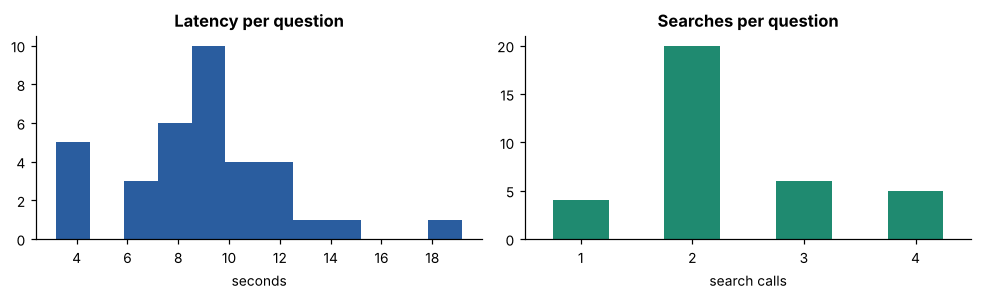

In [9]:
Q = json.load(open("results/qa_eval.json")); m = Q["metrics"]
summary = pd.DataFrame({"value": {
    "questions (30 in-scope, 5 out-of-scope)": m["questions"],
    "citation check passed": f"{m['citation_pass_rate']:.0%}",
    "fabricated chunk IDs": m["fabricated_id_count"],
    "out-of-scope correctly declined": f"{m['out_of_scope_not_covered']}/{m['out_of_scope_count']}",
    "in-scope wrongly declined": m["in_scope_not_covered"],
    "gold source cited (in-scope)": f"{round(m['cited_gold_rate']*m['in_scope_count'])}/{m['in_scope_count']}",
    "mean searches per question": round(m["mean_searches"], 1),
    "mean latency (s)": round(m["mean_latency_s"], 1),
    "total tokens": f"{m['total_tokens']:,}",
    "estimated cost, all 35 (USD)": round(m["estimated_cost_usd"], 2)}})
display(summary)

qs = pd.DataFrame(Q["questions"])
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].hist(qs["latency_s"], bins=12, color=BLUE); ax[0].set_title("Latency per question"); ax[0].set_xlabel("seconds")
qs["searches"].value_counts().sort_index().plot.bar(ax=ax[1], color=TEAL, rot=0)
ax[1].set_title("Searches per question"); ax[1].set_xlabel("search calls")
plt.tight_layout(); plt.show()

**Hand review of the 6 answers that did not cite the gold clip** (retrieval can find a valid but different source): 3 were fully fine; 3 were partial. Across all 34 points reviewed, **29 were fully supported, 5 partial, 0 contradicting**. The partial ones were:

| Question | Problem found |
|---|---|
| q02 | Missed the "stop at 2–3/10 pain" rule; one point misread a clip |
| q09 | Wrongly said the library has no box height |
| q22 | Missed a hamstring-risk point |

Citation presence and ID provenance do not prove the cited text *supports* the claim. That gap is what the **Verifier** targets: a fresh-context model that sees only each point and its cited chunk text, with up to 2 Coach retries.

In [10]:
from src import verifier
print(inspect.getsource(verifier.VerifierResult))
print(Path("prompts/verifier.v2.md").read_text()[:900], "...")

class VerifierResult(_Strict):
    verdict: Literal["pass", "fail"]
    items: list[VerifierItem]
    phase_rule_ok: bool
    summary_matches_diff: bool
    addresses_request: bool | None

# Verifier agent (v2)

You check another agent's work before it reaches the athlete, following the
shared rules above. You see only what is in the message: the changes (mode
`program`) or the answer (mode `answer`), the athlete's request, and the
`evidence` — the text of every cited chunk, keyed by chunk ID. You have no
other knowledge of the library; judge only against that evidence.

## What to check

1. **Support, item by item.** For each change (by `path`) or answer point
   (path `points[i]`), compare what it states — exercises, sets, reps, loads,
   durations, pain thresholds, timing, advice — with its cited evidence:
   - `supported`: the evidence states it, or it is a direct unit conversion
     (cm ↔ in, kg ↔ lb) of what the evidence states.
   - `partly`: the gist is there but a detail (a n

## 6. Planner agent
The Planner turns a profile (training age, lifts, available days, equipment, event date, knee status) into a **periodized program**: a 6-month long-conjugate macrocycle plus a tendon-rehab track. Every prescription must come from a **template I reviewed by hand**, and every template line carries a citation to a transcript chunk.

Graph: `context → planner ⇄ tools → review (8 code checks, ≤2 retries) → approve (interrupt) → save`. Plans are saved as new versions and never overwritten; if I decline or request changes, nothing is saved.

The checks are deterministic code, not an LLM. To show them without private data, the cell below uses the **synthetic** test template (made-up exercises and chunk IDs).

In [11]:
from tests.test_planner_checks import candidate, check
from tests.planner_fixtures import C, C2, MON, day, profile, session, week
from datetime import timedelta

def show(title, failures):
    print(f"{title}: {'PASS (no failures)' if not failures else ''}")
    for f in failures[:2]: print(f"   [{f.check}] {f.path}: {f.reason}")
    if len(failures) > 2: print(f"   ... and {len(failures) - 2} more of the same kind")

show("1. Valid program", check(candidate()))
w = week(days=[day(MON, "jump", [session("depth jump", 3, 5, ("in", 24.0), (C2,))])])
show("2. Depth jump box too high (template says ~16 in)", check(candidate(weeks=[w])))
w = week(days=[day(MON, "lift", [session("front squat")])])
show("3. Exercise not in the template, no deviation reason", check(candidate(weeks=[w])))
show("4. Cites a chunk the Planner never retrieved", check(candidate(), retrieved={C}))
show("5. Athlete has no rack or box", check(candidate(), who=profile(equipment=["barbell"])))

1. Valid program: PASS (no failures)
2. Depth jump box too high (template says ~16 in): 
   [fidelity] weeks[2026-11-02].days[2026-11-02].sessions[0]: depth jump: intensity 24 in outside 15.7-15.7; add a deviation
3. Exercise not in the template, no deviation reason: 
   [fidelity] weeks[2026-11-02].days[2026-11-02].sessions[0]: front squat is not in synth_macro volume / lift; add a deviation
4. Cites a chunk the Planner never retrieved: 
   [provenance] mesocycles[1]: cites not retrieved this run: vidBBBBBBBB@0#1
5. Athlete has no rack or box: 
   [equipment] weeks[2026-11-02].days[2026-11-02].sessions[0]: back squat needs rack
   [equipment] weeks[2026-11-02].days[2026-11-04].sessions[0]: back squat needs rack
   ... and 4 more of the same kind


**Status.** The Planner graph, schema, store, checks and UI Plan tab are built and unit-tested. My first end-to-end plan from the real templates is next (≈ $0.25 per plan). The templates themselves were reviewed on Nov 6: training days (about 3 hard days), 4-week months 4–6, THP-style unload weeks, event-driven shortening and a reactive flare-up stage.

## 7. Tests
The whole suite mocks the models and blocks the network, so it is free and safe to run anywhere.

In [12]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--no-header", "--color=no", "--tb=no"],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout.strip().splitlines()[-1])

202 passed, 3 skipped in 4.80s


## 8. Decisions and challenges
- **Claude API only for chat, local embeddings.** A local `qwen3:4b` took ~8 minutes per prompt on my CPU-only Intel Mac, so Sonnet runs the Coach, Planner and Verifier. `nomic-embed-text` runs locally on Ollama.
- **Privacy.** I approved sending transcript chunks to the Claude API; tracing stays local (no LangSmith) and the Streamlit UI is bound to localhost.
- **Narrow red-flag rule.** The first safety rule referred every tendon ache to a physio, which made the Coach useless for its main use case. It now fires only on explicit symptoms (19 labelled cases).
- **Everything from the transcripts.** The Planner may only use my reviewed templates, and Coach claims must cite a retrieved chunk.
- **Data collection.** YouTube rate-limited collection twice (≈24 h and ≈4.5 days), so collection runs slowly on my own machine.

## 9. Remaining work

| Priority | Item |
|---|---|
| Next | Re-run the Coach evaluation with prompt v4 and the Verifier (≈ $1.30); first real Planner run and Verifier fault test |
| Next | Chat plan requests routed to the Planner, with a red-flag check on free-text requests |
| Then | Coach reads my profile and plan; training log and gate checks (pain, missed sessions) |
| Then | Evaluation: red-team safety cases, no-retrieval baseline, single-agent vs. multi-agent comparison, planning questions |
| If time | MCP server for `search_library`, collecting ~100 newer videos, planner variety within THP principles |
| Cut first if late | MCP, failure-mode labelling. Safety and citations are never cut. |

## 10. Question for feedback
I currently have two task agents (a Coach for questions, a Planner for programs), a fresh-context Verifier, and two code gates. **Is that more agent structure than this problem needs?** Would you recommend one coaching agent with both tool sets? I plan to build a single-agent version and compare the two on the same questions (citation pass rate, Verifier failures, safety cases, cost), but I would value your view before I finalize the architecture.